# Odometry Exercise 2 — 轮子半径（CSY 版）

基于课程笔记本 *odometry-exercise-02-wheel-radius*，改成直接读你的数据。所有长度单位都是 **mm**。

- **日志**：`Go_Straight`（按目标距离行驶，这次用了 +50 / +100 / +180 / −100 / −180 mm）通过 Wi-Fi 发出、`wifi_logger.py` 保存的 `trial_*.csv`，上传到本文件夹的 `data/`。
- **测量表**：Google 表格 **Ex2_测量记录表**，只有四列：编号、CSV、方向、实际距离(mm)。

日志里只有编码器计数，本笔记本用和 `OdometryModel.cpp` 相同的欧拉模型（轮半径 16.0 mm、轮距 90.0 mm、CPR 358.3）换算出里程计的 x、y、θ。16.0 mm 就是公式里的旧半径 r_old。
小车停车用的也是 16.0 mm 换算的计数，所以报告距离约等于命令距离，笔记本据此自动分组，不需要在表里填条件或时间（时长取 CSV 中 `time_ms` 的最大值）。

**最后用最小二乘法拟合「报告距离 = k × 实际距离」，由斜率 k 求出真实轮半径 r = 16.0 / k。**

`USE_EXAMPLE_DATA = False` 时读你的真实数据；改成 `True` 可以看合成示例（不代表你的小车）。

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", context="notebook")
rng = np.random.default_rng(2026)

ENCODER_CPR = 358.3   # counts per wheel revolution (fixed)


def count_change(current, previous):
    # signed 32-bit wrap-safe difference, as OdometryModel_c::countChange
    d = int(current) - int(previous)
    if d > 2**31 - 1:
        d -= 2**32
    if d < -2**31:
        d += 2**32
    return d


def replay_odometry(left_counts, right_counts, radius_mm, separation_mm, cpr=ENCODER_CPR):
    # Same first-order Euler update as OdometryModel.cpp: the first sample is
    # the baseline; each step translates along the OLD heading, then turns.
    x = y = theta = 0.0
    xs, ys, ts = [0.0], [0.0], [0.0]
    for i in range(1, len(left_counts)):
        s_left = count_change(left_counts[i], left_counts[i - 1]) * 2 * np.pi * radius_mm / cpr
        s_right = count_change(right_counts[i], right_counts[i - 1]) * 2 * np.pi * radius_mm / cpr
        ds = (s_left + s_right) / 2
        x += ds * np.cos(theta)
        y += ds * np.sin(theta)
        theta += (s_right - s_left) / separation_mm
        xs.append(x); ys.append(y); ts.append(theta)
    return np.array(xs), np.array(ys), np.array(ts)

## 1. 设置

运行时会请求挂载 Google Drive 和读取表格，用**和这个 Drive 相同的 Google 账号**登录。五次试验全部用于拟合（没有留出组）。

In [2]:
USE_EXAMPLE_DATA = False

DATA_FOLDER = "/content/drive/MyDrive/robot_system/Ex2_wheel_radius_轮子半径误差/data"
SHEET_ID = "1a7xj99-zJZJOIvTKEfxU7SQdRQwrdVFTsPTejRK_-4I"          # Ex2_测量记录表
SHEET_TAB = "测量记录"

MODEL_WHEEL_RADIUS_MM = 16.0        # r_standard, same as Go_Straight's NOMINAL_WHEEL_RADIUS_MM
MODEL_WHEEL_SEPARATION_MM = 90.0

print("Using:", "synthetic example" if USE_EXAMPLE_DATA else DATA_FOLDER)

Using: /content/drive/MyDrive/robot_system/Ex2_wheel_radius_轮子半径误差/data


## 2. 合成示例

只在示例模式下使用，不需要修改。格式和 `wifi_logger.py` 的 CSV、和「测量记录」表完全一样。合成小车的“真实”轮半径是 16.6 mm，所以它会比命令距离走得远一点。

In [3]:
def make_example_log(target_mm, true_radius_mm=16.6, seed=0):
    # robot stops when its counts reach target_mm converted with 16.0 mm
    r = np.random.default_rng(seed)
    target_counts = target_mm / (2 * np.pi * 16.0) * ENCODER_CPR
    sign = np.sign(target_counts)
    counts_per_s = 260 + r.normal(0, 5)
    drive_ms = int(abs(target_counts) / counts_per_s * 1000)
    coast = sign * abs(r.normal(2, 0.5))
    rows = []
    for t in range(0, 500 + drive_ms + 1000, 10):
        if t < 500:
            c = 0.0
        elif t < 500 + drive_ms:
            c = sign * counts_per_s * (t - 500) / 1000
        else:
            c = target_counts + coast
        left, right = int(round(c + r.normal(0, 0.3))), int(round(c))
        pwm = sign * 40.0 if 500 <= t < 500 + drive_ms else 0.0
        rows.append([1, t, pwm, pwm, left, right, left - right])
    log = pd.DataFrame(rows, columns=["run", "time_ms", "left_pwm", "right_pwm",
                                      "left_counts", "right_counts", "diff"])
    true_distance_mm = abs(target_counts + coast) / ENCODER_CPR * 2 * np.pi * true_radius_mm
    return log, true_distance_mm


example_logs, example_rows = {}, []
for n, target in enumerate([50, 100, 180, -100, -180], start=1):
    name = f"example_trial_{n}.csv"
    example_logs[name], true_mm = make_example_log(target, seed=n)
    example_rows.append({"编号": n, "CSV": name, "方向": "前进" if target > 0 else "后退",
                         "实际距离(mm)": round(true_mm + rng.normal(0, 0.8), 1)})
example_sheet = pd.DataFrame(example_rows)
example_sheet.head()

,编号,CSV,方向,实际距离(mm)
0,1,example_trial_1.csv,前进,51.9
1,2,example_trial_2.csv,前进,104.4
2,3,example_trial_3.csv,前进,185.4
3,4,example_trial_4.csv,后退,105.4
4,5,example_trial_5.csv,后退,187.7


## 3. 读取测量表和日志

表里四列：`编号`、`CSV`、`方向`（前进/后退）、`实际距离(mm)`（填正数，方向决定正负）。找不到文件的行会被跳过并列出来。不想要的试验直接从表里删掉那一行即可（CSV 文件可以保留）。
每个试验自动得到：`condition_mm`（报告距离四舍五入到 10 mm，即命令距离）和 `duration_ms`（CSV 中 `time_ms` 的最大值）。

In [4]:
if USE_EXAMPLE_DATA:
    sheet_table = example_sheet.copy()
    read_log = lambda name: example_logs[name]
else:
    from google.colab import auth, drive
    drive.mount("/content/drive")
    auth.authenticate_user()
    import gspread
    from google.auth import default
    creds, _ = default()
    sheet = gspread.authorize(creds).open_by_key(SHEET_ID).worksheet(SHEET_TAB)
    sheet_table = pd.DataFrame(sheet.get_all_records())
    read_log = lambda name: pd.read_csv(Path(DATA_FOLDER) / name, comment="#")

sheet_table.columns = [str(c).strip() for c in sheet_table.columns]
measurements = sheet_table.rename(columns={
    "编号": "trial_num", "CSV": "csv_file", "方向": "direction", "实际距离(mm)": "measured_mm"})
measurements = measurements.replace("", np.nan).dropna(subset=["trial_num", "csv_file"])
measurements["trial_num"] = measurements["trial_num"].astype(int)
measurements["csv_file"] = measurements["csv_file"].astype(str).str.strip()
measurements["direction"] = measurements["direction"].astype(str).str.strip()
sign = np.where(measurements["direction"].isin(["后退", "reverse", "backward"]), -1.0, 1.0)
measurements["measured_distance_mm"] = sign * pd.to_numeric(measurements["measured_mm"]).abs()
assert measurements["trial_num"].is_unique, "编号 must be different on every row"

logs, frames, skipped = {}, [], []
for _, m in measurements.iterrows():
    try:
        log = read_log(m["csv_file"])
    except (FileNotFoundError, KeyError):
        skipped.append(f"编号 {m['trial_num']}: {m['csv_file']} not found")
        continue
    log = log.sort_values("time_ms").reset_index(drop=True)
    logs[m["trial_num"]] = log
    x, y, theta = replay_odometry(log["left_counts"].to_numpy(), log["right_counts"].to_numpy(),
                                  MODEL_WHEEL_RADIUS_MM, MODEL_WHEEL_SEPARATION_MM)
    frames.append(pd.DataFrame({
        "test_name": "translation",
        "trial_num": m["trial_num"],
        "sample_time_ms": log["time_ms"],
        "left_encoder_count": log["left_counts"],
        "right_encoder_count": log["right_counts"],
        "odometry_x_mm": x,
        "odometry_y_mm": y,
        "odometry_theta_rad": theta,
    }))

for s in skipped:
    print("Skipped (CSV not in data/):", s)
if not frames:
    raise SystemExit("No logs loaded - check DATA_FOLDER and the CSV names in the sheet.")

data = pd.concat(frames, ignore_index=True)
print(f"Loaded {len(logs)} trial(s), {len(data)} rows")
data.head()

Mounted at /content/drive
Loaded 5 trial(s), 1546 rows


,test_name,trial_num,sample_time_ms,left_encoder_count,right_encoder_count,odometry_x_mm,odometry_y_mm,odometry_theta_rad
0,translation,1,15,0,0,0.0,0.0,0.0
1,translation,1,25,0,0,0.0,0.0,0.0
2,translation,1,35,0,0,0.0,0.0,0.0
3,translation,1,45,0,0,0.0,0.0,0.0
4,translation,1,55,0,0,0.0,0.0,0.0


## 4. 经过时间

每次试验从 0 秒开始画图（课程原代码）。

In [5]:
data = data.loc[data["test_name"] == "translation"].copy()
data = data.sort_values(["trial_num", "sample_time_ms"])
data["elapsed_s"] = (
    data["sample_time_ms"]
    - data.groupby("trial_num")["sample_time_ms"].transform("first")
) / 1000
data["trial_label"] = "Trial " + data["trial_num"].astype(str)

data[["trial_num", "sample_time_ms", "elapsed_s"]].head()

,trial_num,sample_time_ms,elapsed_s
0,1,15,0.00
1,1,25,0.01
2,1,35,0.02
3,1,45,0.03
4,1,55,0.04


## 5. 两个编码器的计数

记录下来的车轮运动，不是物理距离的独立测量。看方向对不对、左右两条线是否基本重合。开头 0.5 s 和结尾 1 s 是静止和滑行记录。

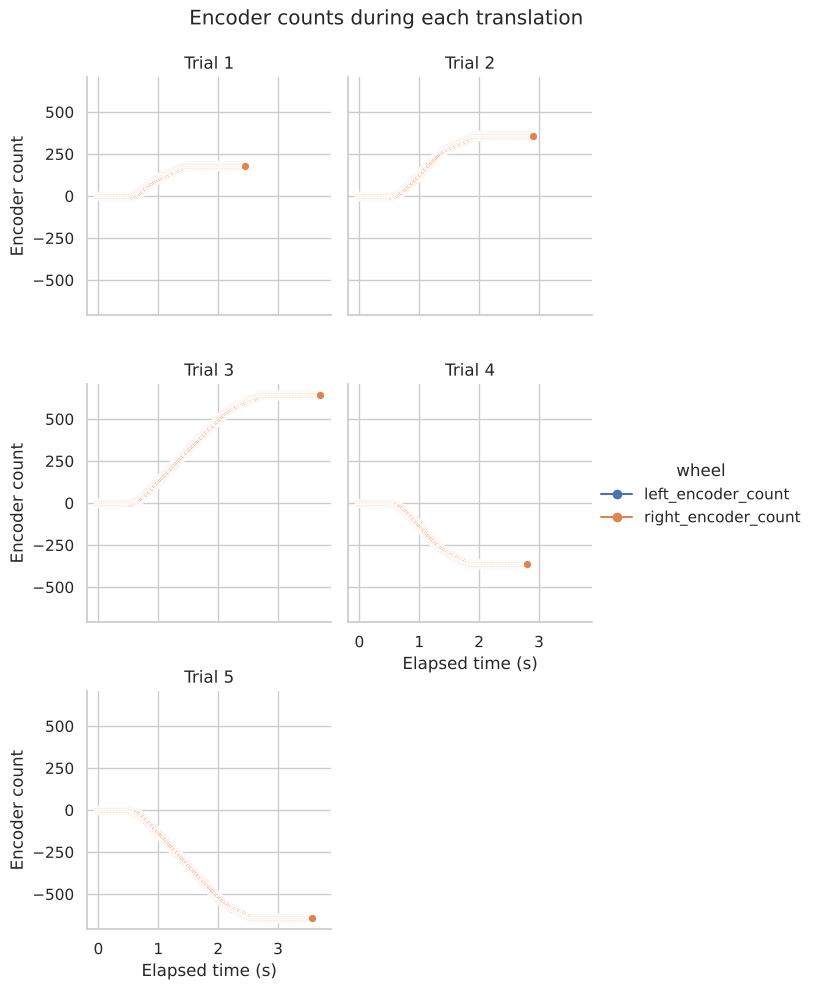

In [6]:
encoder_plot_data = data.melt(
    id_vars=["trial_num", "trial_label", "elapsed_s"],
    value_vars=["left_encoder_count", "right_encoder_count"],
    var_name="wheel",
    value_name="encoder_count",
)

grid = sns.relplot(
    data=encoder_plot_data,
    x="elapsed_s",
    y="encoder_count",
    hue="wheel",
    col="trial_label",
    col_wrap=2,
    kind="line",
    marker="o",
    estimator=None,
    height=3.2,
)
grid.set_axis_labels("Elapsed time (s)", "Encoder count")
grid.set_titles("{col_name}")
grid.figure.suptitle("Encoder counts during each translation", y=1.03)
plt.show()

## 6. 里程计报告的 x-y 路径

模型算出来的轨迹，不是外部测量。用来看模型有没有报告明显的横向移动。

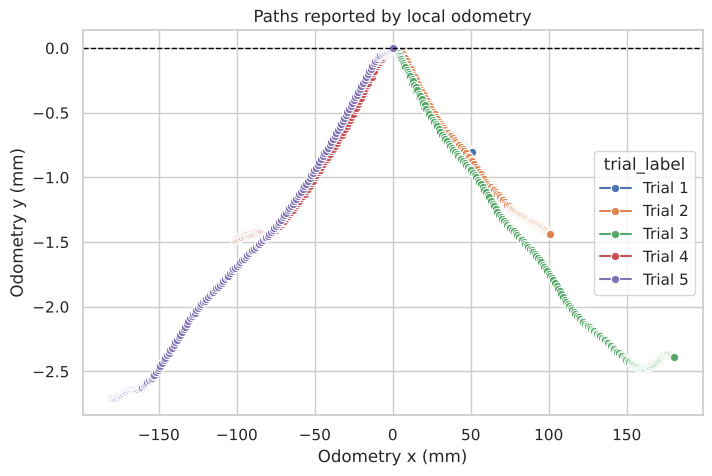

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.lineplot(
    data=data,
    x="odometry_x_mm",
    y="odometry_y_mm",
    hue="trial_label",
    marker="o",
    estimator=None,
    ax=ax,
)
ax.axhline(0, color="black", linewidth=1, linestyle="--")
ax.set(
    title="Paths reported by local odometry",
    xlabel="Odometry x (mm)",
    ylabel="Odometry y (mm)",
)
plt.show()

## 7. 每次试验的结果

用**第一行和最后一行**算报告的 x 位移、横向变化（mm）和航向变化（°），并合并你的实测距离。
`condition_mm` 是自动识别的命令距离；`straight_enough` 检查直线假设（横向变化 ≤ 5 mm 且航向变化 ≤ 3°），不够直的试验建议从表里删掉那一行。

In [8]:
trial_summary = (
    data.groupby("trial_num", as_index=False)
    .agg(
        duration_ms=("sample_time_ms", "max"),
        initial_x_mm=("odometry_x_mm", "first"),
        final_x_mm=("odometry_x_mm", "last"),
        initial_y_mm=("odometry_y_mm", "first"),
        final_y_mm=("odometry_y_mm", "last"),
        initial_heading_rad=("odometry_theta_rad", "first"),
        final_heading_rad=("odometry_theta_rad", "last"),
    )
)
trial_summary["reported_distance_mm"] = trial_summary["final_x_mm"] - trial_summary["initial_x_mm"]
trial_summary["reported_sideways_change_mm"] = trial_summary["final_y_mm"] - trial_summary["initial_y_mm"]
trial_summary["reported_heading_change_deg"] = np.degrees(
    trial_summary["final_heading_rad"] - trial_summary["initial_heading_rad"])

comparison = trial_summary.merge(measurements[["trial_num", "csv_file", "direction", "measured_distance_mm"]],
                                 on="trial_num")
comparison["condition_mm"] = (comparison["reported_distance_mm"] / 10).round().astype(int) * 10
comparison["straight_enough"] = ((comparison["reported_sideways_change_mm"].abs() <= 5)
                                 & (comparison["reported_heading_change_deg"].abs() <= 3))

comparison[["trial_num", "csv_file", "condition_mm", "direction", "duration_ms",
            "measured_distance_mm", "reported_distance_mm", "reported_sideways_change_mm",
            "reported_heading_change_deg", "straight_enough"]].round(2)

,trial_num,csv_file,condition_mm,direction,duration_ms,measured_distance_mm,reported_distance_mm,reported_sideways_change_mm,reported_heading_change_deg,straight_enough
0,1,5cm.csv,50,前进,2470,52.0,50.78,-0.80,-0.36,True
1,2,10cm.csv,100,前进,2912,103.0,101.00,-1.44,-0.71,True
2,3,18cm.csv,180,前进,3712,181.0,180.53,-2.39,-0.18,True
3,4,-10cm.csv,-100,后退,2815,-106.0,-101.13,-1.48,0.18,True
4,5,-18cm.csv,-180,后退,3582,-187.0,-180.81,-2.70,-0.18,True


## 8. 每次试验单独估算的半径（参考）

课程公式：`r = r_standard × 实际距离 ÷ 报告距离`，每次试验各算一个，用来看散布和前进/后退的差异。最终结果用下一节的最小二乘拟合。

In [9]:
comparison["single_trial_radius_mm"] = (
    MODEL_WHEEL_RADIUS_MM * comparison["measured_distance_mm"] / comparison["reported_distance_mm"]
)
display(comparison[["trial_num", "csv_file", "condition_mm", "measured_distance_mm",
                    "reported_distance_mm", "single_trial_radius_mm"]].round(3))
print("single-trial radius: mean {:.3f} mm, median {:.3f} mm, sd {:.3f} mm".format(
    comparison["single_trial_radius_mm"].mean(), comparison["single_trial_radius_mm"].median(),
    comparison["single_trial_radius_mm"].std()))

single-trial radius: mean 16.412 mm, median 16.385 mm, sd 0.271 mm


,trial_num,csv_file,condition_mm,measured_distance_mm,reported_distance_mm,single_trial_radius_mm
0,1,5cm.csv,50,52.0,50.777,16.385
1,2,10cm.csv,100,103.0,100.996,16.318
2,3,18cm.csv,180,181.0,180.530,16.042
3,4,-10cm.csv,-100,-106.0,-101.134,16.770
4,5,-18cm.csv,-180,-187.0,-180.809,16.548


## 9. 最小二乘拟合：斜率 k → 真实轮半径

编码器计数 n 相同时：

- 报告距离 = (2π · r_standard / N) · n
- 实际距离 = (2π · r_true / N) · n

所以 **报告距离 = k × 实际距离**，其中 **k = r_standard / r_true**，于是 **r_true = r_standard / k**（r_standard = 16.0 mm，N = 358.3）。

把五个点（x = 实际距离，y = 报告距离，单位 mm，前进为正、后退为负）用最小二乘法拟合一条**过原点**的直线：k = Σxy / Σx²。
同时给出 k 的标准误差和由此传递到 r 的不确定度，以及带截距的拟合 y = a·x + b 作对照（截距 b 反映起步/停车/放置带来的固定偏差）。

Least-squares slope (through origin)  k = reported / real = 0.97802  (± 0.00792)
R² = 0.99974
r_true = r_standard / k = 16.0 / 0.97802 = 16.360 mm  (± 0.132 mm)
With intercept: y = 0.97724 x + 1.668 mm  ->  r = 16.373 mm
Forward only:  k = 0.99229 -> r = 16.124 mm   Reverse only: k = 0.96378 -> r = 16.601 mm


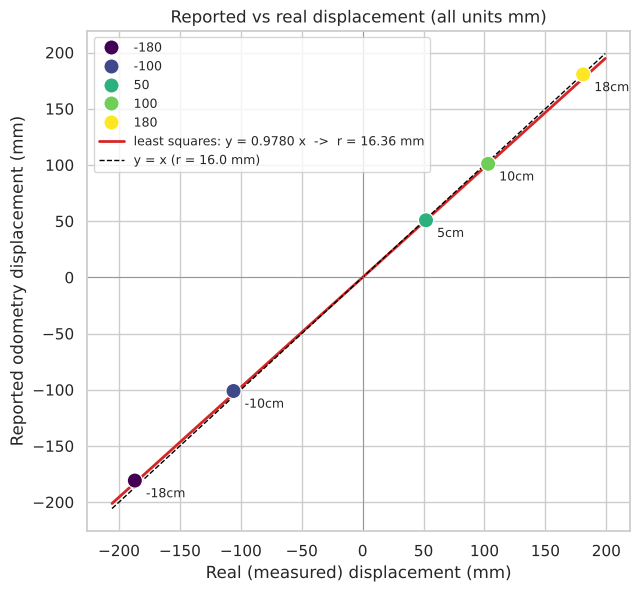

In [10]:
x = comparison["measured_distance_mm"].to_numpy(dtype=float)   # real
y = comparison["reported_distance_mm"].to_numpy(dtype=float)   # reported
n = len(x)

# Least squares through the origin: y = k x
k = np.sum(x * y) / np.sum(x * x)
residuals = y - k * x
k_se = np.sqrt(np.sum(residuals**2) / (n - 1) / np.sum(x * x))
r_true = MODEL_WHEEL_RADIUS_MM / k
r_true_se = MODEL_WHEEL_RADIUS_MM * k_se / k**2
r_squared = 1 - np.sum(residuals**2) / np.sum((y - y.mean())**2)

# For comparison: ordinary least squares with an intercept, y = a x + b
a, b = np.polyfit(x, y, 1)

# Forward-only and reverse-only slopes (through the origin)
fwd, rev = x > 0, x < 0
k_fwd = np.sum(x[fwd] * y[fwd]) / np.sum(x[fwd] ** 2)
k_rev = np.sum(x[rev] * y[rev]) / np.sum(x[rev] ** 2)

print(f"Least-squares slope (through origin)  k = reported / real = {k:.5f}  (± {k_se:.5f})")
print(f"R² = {r_squared:.5f}")
print(f"r_true = r_standard / k = {MODEL_WHEEL_RADIUS_MM:.1f} / {k:.5f} = {r_true:.3f} mm  (± {r_true_se:.3f} mm)")
print(f"With intercept: y = {a:.5f} x + {b:.3f} mm  ->  r = {MODEL_WHEEL_RADIUS_MM / a:.3f} mm")
print(f"Forward only:  k = {k_fwd:.5f} -> r = {MODEL_WHEEL_RADIUS_MM / k_fwd:.3f} mm   "
      f"Reverse only: k = {k_rev:.5f} -> r = {MODEL_WHEEL_RADIUS_MM / k_rev:.3f} mm")

fig, ax = plt.subplots(figsize=(7, 6.5))
sns.scatterplot(data=comparison, x="measured_distance_mm", y="reported_distance_mm",
                hue="condition_mm", palette="viridis", s=120, ax=ax, zorder=3)
for _, row in comparison.iterrows():
    ax.annotate(row["csv_file"].replace(".csv", ""), (row["measured_distance_mm"], row["reported_distance_mm"]),
                textcoords="offset points", xytext=(8, -12), fontsize=9)
span = np.array([min(x.min(), 0) * 1.1, max(x.max(), 0) * 1.1])
ax.plot(span, k * span, color="tab:red", linewidth=2,
        label=f"least squares: y = {k:.4f} x  ->  r = {r_true:.2f} mm")
ax.plot(span, span, color="black", linestyle="--", linewidth=1, label="y = x (r = 16.0 mm)")
ax.axhline(0, color="grey", linewidth=0.5); ax.axvline(0, color="grey", linewidth=0.5)
ax.set(title="Reported vs real displacement (all units mm)",
       xlabel="Real (measured) displacement (mm)",
       ylabel="Reported odometry displacement (mm)")
ax.legend(loc="upper left", fontsize=9)
plt.show()

## 结论与注意

- 斜率 k < 1 表示里程计报告的距离比实际短，即 16.0 mm 的模型半径偏小，真实（有效）半径更大；k > 1 则相反。
- 拟合得到的 `r_true`（mm）就是之后 `setLeftWheelRadiusMm(...)` / `setRightWheelRadiusMm(...)` 和 Go_Straight 里 `NOMINAL_WHEEL_RADIUS_MM` 要用的值。它是这块地面、这个负载下的**有效**半径，不一定等于用尺子量轮子得到的几何半径。
- 每个条件只有 1 次试验，所以 ± 只反映这 5 个点相对直线的散布；每个条件多做几次能更好地区分随机误差（放置、读数、起停）和系统误差。
- 前进和后退分别拟合的结果如果明显不同，说明存在方向相关的误差（例如打滑、起步方式、测量方式），值得在报告里讨论。